# Video audit

This notebook checks the raw head, left and right videos and compares them with the IMU files.

## 1. Setup

This step loads the config, the manifest and the IMU summary, and checks that ffprobe and PyAV work.

In [1]:
import json, subprocess, shutil, sys, re, time, os, zipfile, hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import yaml, av, cv2
from tqdm import tqdm

# flags
DECODE_ALL = True     # decode every frame of the 45 device clips
DECODE_ROOT = False   # root video gets container and packet checks only

# expected values, always compared and never assumed
EXPECTED = {
    "nb_streams": 1, "codec": "h264", "pix_fmt": "yuv420p",
    "fps": 30.0, "fps_tol": 0.05,
    "n_device_files": 46, "n_clips": 45,
    "frame_tol": 2, "dur_tol_s": 0.1,
    "imu_full_rows": 5400,
    "imu_last_rows": {"head": 1771, "left": 654, "right": 1282},
    "ref_mbps": (5.0, 8.0),
    "root_min_minutes": 20.0,
    "black_luma": 16, "black_std": 8, "black_run_flag": 2,
    "max_distinct_steps": 3,
    "contact_ranks": (1, 2, 8, 14, 15),
}
dev_order = ["head", "left", "right"]

# project folders
PROJECT_ROOT = Path.cwd().resolve().parent
cfg_path = PROJECT_ROOT / "configs" / "config.yaml"
if not cfg_path.exists():
    raise RuntimeError(f"configs\\config.yaml not found in {PROJECT_ROOT}. "
                       f"Open this notebook from <PROJECT_ROOT>\\notebooks (working directory is {Path.cwd()}).")
RAW = PROJECT_ROOT / "raw"
INTERIM = PROJECT_ROOT / "interim"
REPORTS = PROJECT_ROOT / "reports"
for d in [INTERIM / "probe", INTERIM / "pts", INTERIM / "frames", REPORTS]:
    d.mkdir(parents=True, exist_ok=True)

cfg = yaml.safe_load(cfg_path.read_text(encoding="utf-8")) or {}
nominal_fps = float(cfg.get("nominal_fps", 30))
freeze_run = int(cfg.get("thresholds", {}).get("freeze_run_frames", 5))

# small helpers
def split_rel(s):
    return re.split(r"[\\/]", str(s))

def num(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan

def frac(s):
    try:
        a, b = str(s).split("/")
        return float(a) / float(b) if float(b) else np.nan
    except Exception:
        return num(s)

def save_csv(df, name):
    try:
        df.to_csv(REPORTS / name, index=False)
        print(f"saved reports\\{name} ({len(df)} rows)")
    except OSError as e:
        print(f"could not write {name}: {e}")

def save_npz(path, **arrays):
    tmp = path.parent / (path.name + ".tmp")
    with open(tmp, "wb") as f:
        np.savez(f, **arrays)
    os.replace(tmp, path)

def load_npz(path):
    if not path.exists():
        return None
    try:
        with np.load(path) as z:
            return {k: z[k] for k in z.files}
    except Exception:
        return None

# load the tables
man = pd.read_csv(REPORTS / "raw_manifest.csv")
imu = pd.read_csv(REPORTS / "02_imu_file_summary.csv")
imu["base_name"] = imu["base_name"].astype(str).str.replace(r"\.txt$", "", regex=True)
imu = imu.drop_duplicates("base_name").copy()

# video table used by every later step
vids = man[man["kind"].isin(["video", "root_video"])].copy()
vids["base"] = vids["rel_path"].map(lambda s: Path(*split_rel(s)).stem)
vids["path"] = vids["rel_path"].map(lambda s: RAW.joinpath(*split_rel(s)))
vids["is_root"] = vids["kind"].eq("root_video")
vids["dup_suffix"] = [("" if pd.isna(x) else str(x).strip()) for x in vids["dup_suffix"]]
vids["is_dup"] = vids["dup_suffix"].ne("") | vids["base"].str.contains(r"\(\d+\)$")
vids["key"] = vids["base"].str.replace(r"\(\d+\)$", "", regex=True)
cn = pd.to_numeric(vids["clip_no"], errors="coerce")
vids["clip_no"] = cn.fillna(pd.to_numeric(vids["key"].str.extract(r"(\d+)$")[0], errors="coerce"))
vids.loc[vids["is_root"], "clip_no"] = np.nan
vids = vids.reset_index(drop=True)

# chunk rank = position of the clip in its device, duplicates share the rank of the original
dev_clips = vids[~vids["is_root"] & ~vids["is_dup"]].copy()
dev_clips["chunk_rank"] = dev_clips.groupby("device")["clip_no"].rank(method="first")
rank_map = dict(zip(dev_clips["key"], dev_clips["chunk_rank"]))
vids["chunk_rank"] = vids["key"].map(rank_map)
clips = vids[~vids["is_root"] & ~vids["is_dup"]].copy()   # the 45 clips
root = vids[vids["is_root"]].copy()

# tools check
if shutil.which("ffprobe") is None:
    raise RuntimeError("ffprobe is not on PATH")
ff_line = subprocess.run(["ffprobe", "-version"], capture_output=True, text=True, timeout=30).stdout.splitlines()[0]
first = vids.iloc[0]
try:
    r = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
                        "stream=codec_name,width,height", "-of", "csv=p=0", str(first["path"])],
                       capture_output=True, text=True, timeout=60)
    ffprobe_test = r.stdout.strip() or r.stderr.strip()[:100]
    with av.open(str(first["path"])) as c:
        s = c.streams.video[0]
        av_test = f"{s.codec_context.name} {s.codec_context.width}x{s.codec_context.height}"
except Exception as e:
    ffprobe_test, av_test = "failed", f"failed ({e})"

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)
print("av", av.__version__, "| cv2", cv2.__version__)
print(ff_line)
print("first file:", first["base"], "| ffprobe:", ffprobe_test, "| pyav:", av_test)
print("project root:", PROJECT_ROOT)
print(f"config: nominal_fps {nominal_fps:g}, freeze_run_frames {freeze_run}, devices {list(cfg.get('devices', {}))}")
print(f"video files: {(~vids['is_root']).sum()} in device folders + {len(root)} root "
      f"(expected {EXPECTED['n_device_files']} + 1), imu summary rows {len(imu)}")
missing = [b for b, p in zip(vids["base"], vids["path"]) if not p.exists()]
print("missing video files:", missing if missing else "none")

python 3.13.13 | numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2
av 19.0.1 | cv2 5.0.0
ffprobe version 9.0.2-full_build-www.gyan.dev Copyright (c) 2007-2026 the FFmpeg developers
first file: a45140-H-0036 | ffprobe: hevc,1920,1080 | pyav: hevc 1920x1080
project root: C:\workstation\3RD YEAR\ego_pipeline
config: nominal_fps 30, freeze_run_frames 5, devices ['head', 'left', 'right']
video files: 46 in device folders + 1 root (expected 46 + 1), imu summary rows 47
missing video files: none


## 2. Container probe

This step runs ffprobe on all 47 files and saves the raw json and a summary table.

In [2]:
PROBE_DIR = INTERIM / "probe"

def run_probe(path):
    cmd = ["ffprobe", "-v", "error", "-show_format", "-show_streams", "-of", "json", str(path)]
    r = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=180)
    if r.returncode != 0:
        raise RuntimeError(r.stderr.strip()[:200] or "ffprobe failed")
    return json.loads(r.stdout)

def probe_row(js):
    fmt = js.get("format", {})
    streams = js.get("streams", [])
    vs = next((s for s in streams if s.get("codec_type") == "video"), {})
    ftags = {k.lower(): v for k, v in (fmt.get("tags") or {}).items()}
    stags = {k.lower(): v for k, v in (vs.get("tags") or {}).items()}
    rot = num(stags.get("rotate"))
    for sd in (vs.get("side_data_list") or []):
        if "rotation" in sd:
            rot = num(sd["rotation"])
    if np.isnan(rot):
        rot = 0.0
    w, h = vs.get("width"), vs.get("height")
    br = num(vs.get("bit_rate"))
    if np.isnan(br):
        br = num(fmt.get("bit_rate"))
    return {
        "nb_streams": int(fmt.get("nb_streams", len(streams))),
        "stream_types": "+".join(s.get("codec_type", "?") for s in streams),
        "codec_name": vs.get("codec_name"), "profile": vs.get("profile"), "level": num(vs.get("level")),
        "width": w, "height": h, "res": f"{w}x{h}" if w else None,
        "pix_fmt": vs.get("pix_fmt"), "bits_per_raw_sample": num(vs.get("bits_per_raw_sample")),
        "r_frame_rate_str": vs.get("r_frame_rate"), "r_frame_rate": frac(vs.get("r_frame_rate")),
        "avg_frame_rate_str": vs.get("avg_frame_rate"), "avg_frame_rate": frac(vs.get("avg_frame_rate")),
        "time_base": vs.get("time_base"), "nb_frames": num(vs.get("nb_frames")),
        "stream_duration_s": num(vs.get("duration")), "format_duration_s": num(fmt.get("duration")),
        "bit_rate": br, "format_name": fmt.get("format_name"),
        "major_brand": ftags.get("major_brand"),
        "encoder": stags.get("encoder") or ftags.get("encoder"),
        "creation_time": ftags.get("creation_time") or stags.get("creation_time"),
        "rotation": rot, "color_range": vs.get("color_range"), "color_space": vs.get("color_space"),
        "field_order": vs.get("field_order"), "has_b_frames": num(vs.get("has_b_frames")),
        "audio_present": any(s.get("codec_type") == "audio" for s in streams),
    }

rows, probe_errors = [], []
for v in tqdm(list(vids.itertuples()), desc="ffprobe"):
    base_info = {"base": v.base, "device": v.device, "clip_no": v.clip_no, "dup_suffix": v.dup_suffix,
                 "is_dup": v.is_dup, "is_root": v.is_root, "chunk_rank": v.chunk_rank}
    cache = PROBE_DIR / f"{v.base}.json"
    js = None
    if cache.exists():
        try:
            js = json.loads(cache.read_text(encoding="utf-8"))
            if "format" not in js:
                js = None
        except Exception:
            js = None
    try:
        if js is None:
            js = run_probe(v.path)
            cache.write_text(json.dumps(js, indent=1), encoding="utf-8")
        rows.append({**base_info, **probe_row(js), "error": ""})
    except Exception as e:
        probe_errors.append((v.base, str(e)[:100]))
        rows.append({**base_info, "error": str(e)[:100]})

probe_df = pd.DataFrame(rows)
if "res" not in probe_df.columns:
    probe_df["res"] = None
save_csv(probe_df.drop(columns=["is_dup", "is_root", "chunk_rank"]), "03_probe_summary.csv")
print(f"probed {len(probe_df) - len(probe_errors)} of {len(probe_df)} files, {len(probe_errors)} failed")
for b, e in probe_errors[:10]:
    print("  failed:", b, e)

group_cols = ["codec_name", "profile", "level", "pix_fmt", "res", "avg_frame_rate_str"]
def group_counts(df):
    if df.empty or "codec_name" not in df.columns:
        return pd.DataFrame(columns=group_cols + ["files"])
    return df.groupby(group_cols, dropna=False).size().reset_index(name="files")

dev_groups = group_counts(probe_df[~probe_df["is_root"]])
root_groups = group_counts(probe_df[probe_df["is_root"]])
print("\ndevice files (46):")
print(dev_groups.to_string(index=False))
print("\nroot video:")
print(root_groups.to_string(index=False))

ffprobe: 100%|██████████| 47/47 [00:05<00:00,  8.41it/s]

saved reports\03_probe_summary.csv (47 rows)
probed 47 of 47 files, 0 failed

device files (46):
codec_name profile  level  pix_fmt       res avg_frame_rate_str  files
      hevc    Main  123.0 yuvj420p 1920x1080               30/1     46

root video:
codec_name profile  level pix_fmt       res avg_frame_rate_str  files
      h264    High   42.0 yuv420p 1920x1080 446636250/14745071      1


## 3. Packet timing

This step reads every packet timestamp without decoding and saves the pts arrays.

In [3]:
PTS_DIR = INTERIM / "pts"

def read_packets(path):
    pts, dts, size, key = [], [], [], []
    with av.open(str(path)) as c:
        s = c.streams.video[0]
        tb = float(s.time_base)
        for p in c.demux(s):
            if p.size == 0 and p.pts is None and p.dts is None:
                continue   # flush packet
            pts.append(np.nan if p.pts is None else p.pts * tb)
            dts.append(np.nan if p.dts is None else p.dts * tb)
            size.append(p.size)
            key.append(bool(p.is_keyframe))
    return {"pts": np.array(pts, dtype=np.float64), "dts": np.array(dts, dtype=np.float64),
            "size": np.array(size, dtype=np.int64), "key": np.array(key, dtype=bool)}

def packet_stats(a):
    pts, dts, size, key = a["pts"], a["dts"], a["size"], a["key"].astype(bool)
    ps = np.sort(pts[np.isfinite(pts)])
    steps = np.diff(ps)
    med = float(np.median(steps)) if len(steps) else np.nan
    both = np.isfinite(pts) & np.isfinite(dts)
    dts_ok = dts[np.isfinite(dts)]
    pts_ok = pts[np.isfinite(pts)]
    gop = np.diff(np.flatnonzero(key))
    n = len(pts)
    first_pts = float(ps[0]) if len(ps) else np.nan
    last_pts = float(ps[-1]) if len(ps) else np.nan
    span = last_pts - first_pts
    return {
        "n_packets": n,
        "first_pts": first_pts, "last_pts": last_pts,
        "first_dts": float(dts[0]) if n and np.isfinite(dts[0]) else np.nan,
        "start_offset": first_pts,
        "duration_from_pts": span + med if len(steps) else np.nan,
        "mean_fps": (len(ps) - 1) / span if len(steps) and span > 0 else np.nan,
        "step_min_ms": steps.min() * 1000 if len(steps) else np.nan,
        "step_median_ms": med * 1000 if len(steps) else np.nan,
        "step_max_ms": steps.max() * 1000 if len(steps) else np.nan,
        "n_distinct_steps": len(np.unique(np.round(steps * 1000, 1))) if len(steps) else 0,
        "n_nonmonotonic_pts": int((np.diff(pts_ok) < 0).sum()),   # decode order, normal with b-frames
        "n_nonmonotonic_dts": int((np.diff(dts_ok) <= 0).sum()),
        "n_duplicate_pts": int(len(pts_ok) - len(np.unique(pts_ok))),
        "n_gaps_over_1_5_frames": int((steps > 1.5 * med).sum()) if len(steps) else 0,
        "n_keyframes": int(key.sum()),
        "median_gop_frames": float(np.median(gop)) if len(gop) else np.nan,
        "bframes_present": bool(np.any(np.abs(pts[both] - dts[both]) > 1e-6) or np.any(np.diff(pts_ok) < 0)),
        "pkt_size_min": int(size.min()) if n else 0, "pkt_size_median": float(np.median(size)) if n else np.nan,
        "pkt_size_mean": float(size.mean()) if n else np.nan, "pkt_size_max": int(size.max()) if n else 0,
    }

rows, pkt_errors = [], []
for v in tqdm(list(vids.itertuples()), desc="packets"):
    base_info = {"base": v.base, "device": v.device, "clip_no": v.clip_no, "dup_suffix": v.dup_suffix,
                 "is_dup": v.is_dup, "is_root": v.is_root, "chunk_rank": v.chunk_rank}
    f = PTS_DIR / f"{v.base}.npz"
    a = load_npz(f)
    try:
        if a is None:
            a = read_packets(v.path)
            save_npz(f, **a)
        rows.append({**base_info, **packet_stats(a), "error": ""})
    except Exception as e:
        pkt_errors.append((v.base, str(e)[:100]))
        rows.append({**base_info, "error": str(e)[:100]})

pkt_df = pd.DataFrame(rows)
save_csv(pkt_df.drop(columns=["is_dup", "is_root", "chunk_rank"]), "03_packet_timing.csv")
print(f"packet timing for {len(pkt_df) - len(pkt_errors)} of {len(pkt_df)} files, {len(pkt_errors)} failed")
for b, e in pkt_errors[:10]:
    print("  failed:", b, e)
if "n_packets" in pkt_df.columns and pkt_df["n_packets"].notna().any():
    show = pkt_df[~pkt_df["is_root"]].groupby("device")[["n_packets", "mean_fps", "step_min_ms", "step_median_ms",
                                                          "step_max_ms", "n_distinct_steps", "n_gaps_over_1_5_frames"]].agg(["min", "max"])
    print(show.round(3).to_string())

packets: 100%|██████████| 47/47 [00:15<00:00,  3.11it/s]

saved reports\03_packet_timing.csv (47 rows)
packet timing for 47 of 47 files, 0 failed
       n_packets       mean_fps       step_min_ms         step_median_ms         step_max_ms         n_distinct_steps     n_gaps_over_1_5_frames    
             min   max      min   max         min     max            min     max         min     max              min max                    min max
device                                                                                                                                              
head        1771  5400     30.0  30.0      33.333  33.333         33.333  33.333      33.333  33.333                1   1                      0   0
left         654  5400     30.0  30.0      33.333  33.333         33.333  33.333      33.333  33.333                1   1                      0   0
right       1282  5400     30.0  30.0      33.333  33.333         33.333  33.333      33.333  33.333                1   1                      0   0


## 4. Decode and frame checks

This step decodes every frame of the 45 clips and hashes the gray plane to find frozen and black frames.

In [4]:
FR_DIR = INTERIM / "frames"
fc_cols = ["base", "device", "clip_no", "chunk_rank", "n_packets", "n_decoded", "n_decode_errors",
           "decoded_minus_packets", "n_identical_to_prev", "max_identical_run", "n_freeze_runs",
           "longest_freeze_start_frame", "longest_freeze_len", "longest_freeze_start_s",
           "n_black", "max_black_run", "mean_luma", "mean_motion"]

def decode_frames(path, bar=None):
    pts, dig, mu, sd, df = [], [], [], [], []
    errs, prev = 0, None
    with av.open(str(path)) as c:
        s = c.streams.video[0]
        s.thread_type = "AUTO"
        for p in c.demux(s):
            try:
                frames = p.decode()
            except Exception:
                errs += 1
                continue
            for f in frames:
                g = np.ascontiguousarray(f.to_ndarray(format="gray"))
                dig.append(int.from_bytes(hashlib.blake2b(g.tobytes(), digest_size=8).digest(), "little"))
                m, sdv = cv2.meanStdDev(g)
                mu.append(float(m[0][0]))
                sd.append(float(sdv[0][0]))
                small = cv2.resize(g, (64, 36), interpolation=cv2.INTER_AREA).astype(np.int16)
                df.append(np.nan if prev is None else float(np.abs(small - prev).mean()))
                prev = small
                pts.append(np.nan if f.time is None else float(f.time))
                if bar is not None:
                    bar.update(1)
    return {"pts_time": np.array(pts, dtype=np.float64), "digest": np.array(dig, dtype=np.uint64),
            "luma_mean": np.array(mu, dtype=np.float32), "luma_std": np.array(sd, dtype=np.float32),
            "motion": np.array(df, dtype=np.float32), "n_errors": np.array(errs)}

def runs_of(values):
    # start index and length of every run of equal neighbours
    if len(values) == 0:
        return np.array([], dtype=int), np.array([], dtype=int)
    chg = np.flatnonzero(values[1:] != values[:-1]) + 1
    starts = np.concatenate([[0], chg])
    ends = np.concatenate([chg, [len(values)]])
    return starts, ends - starts

def frame_metrics(info, a, n_pk):
    dg, t = a["digest"], a["pts_time"]
    n = len(dg)
    st, ln = runs_of(dg)
    rep = ln >= 2
    long_run = ln >= freeze_run
    black = (a["luma_mean"] < EXPECTED["black_luma"]) & (a["luma_std"] < EXPECTED["black_std"])
    bs, bl = runs_of(black)
    bl = bl[black[bs]] if len(bs) else bl
    row = {**info, "n_packets": n_pk, "n_decoded": n, "n_decode_errors": int(a["n_errors"]),
           "decoded_minus_packets": n - n_pk if n_pk == n_pk else np.nan,
           "n_identical_to_prev": int((ln - 1).sum()), "max_identical_run": int(ln.max()) if n else 0,
           "n_freeze_runs": int(long_run.sum()),
           "longest_freeze_start_frame": np.nan, "longest_freeze_len": 0, "longest_freeze_start_s": np.nan,
           "n_black": int(black.sum()), "max_black_run": int(bl.max()) if len(bl) else 0,
           "mean_luma": float(np.nanmean(a["luma_mean"])) if n else np.nan,
           "mean_motion": float(np.nanmean(a["motion"])) if n > 1 else np.nan}
    if long_run.any():
        k = np.flatnonzero(long_run)[np.argmax(ln[long_run])]
        row["longest_freeze_start_frame"] = int(st[k])
        row["longest_freeze_len"] = int(ln[k])
        row["longest_freeze_start_s"] = float(t[st[k]])
    runs = [{"base": info["base"], "start_frame": int(st[k]), "length": int(ln[k]),
             "start_time_s": float(t[st[k]]), "is_freeze": bool(ln[k] >= freeze_run)} for k in np.flatnonzero(rep)]
    return row, runs

npk = pkt_df.set_index("base")["n_packets"] if "n_packets" in pkt_df.columns else pd.Series(dtype=float)
frame_arrays, decode_fail = {}, []
dec_frames, dec_secs, from_cache = 0, 0.0, 0
if not DECODE_ALL:
    print("DECODE_ALL is False, only cached clips are used")
for v in tqdm(list(clips.itertuples()), desc="clips"):
    f = FR_DIR / f"{v.base}.npz"
    a = load_npz(f)
    if a is not None:
        from_cache += 1
    elif DECODE_ALL:
        try:
            t0 = time.time()
            a = decode_frames(v.path)
            dec_secs += time.time() - t0
            dec_frames += len(a["digest"])
            save_npz(f, **a)
        except Exception as e:
            decode_fail.append((v.base, str(e)[:100]))
            continue
    if a is not None:
        frame_arrays[v.base] = a

if dec_secs > 0:
    print(f"decoded {dec_frames} frames in {dec_secs:.0f} s, average {dec_frames / dec_secs:.0f} frames per second")
print(f"clips with frame data: {len(frame_arrays)} ({from_cache} from cache), decode failures: {len(decode_fail)}")
for b, e in decode_fail[:10]:
    print("  failed:", b, e)

fc_rows, run_rows = [], []
for v in clips.itertuples():
    if v.base in frame_arrays:
        info = {"base": v.base, "device": v.device, "clip_no": v.clip_no, "chunk_rank": v.chunk_rank}
        row, runs = frame_metrics(info, frame_arrays[v.base], npk.get(v.base, np.nan))
        fc_rows.append(row)
        run_rows += [{"file": v.base, **r} for r in runs]
fc = pd.DataFrame(fc_rows, columns=fc_cols)
runs_df = pd.DataFrame(run_rows, columns=["file", "base", "start_frame", "length", "start_time_s", "is_freeze"]).drop(columns=["base"])
if len(fc):
    save_csv(fc.drop(columns=["chunk_rank"]), "03_frame_checks.csv")
    save_csv(runs_df, "03_freeze_runs.csv")
    per = fc.groupby("device").agg(clips=("base", "count"), frames=("n_decoded", "sum"), errors=("n_decode_errors", "sum"),
                                   identical=("n_identical_to_prev", "sum"), longest_run=("max_identical_run", "max"),
                                   freeze_runs=("n_freeze_runs", "sum"), black=("n_black", "sum"))
    print(per.to_string())
    print("clips with freeze runs:", int((fc["n_freeze_runs"] > 0).sum()),
          "| clips with black frames:", int((fc["n_black"] > 0).sum()),
          "| clips where decoded != packets:", int((fc["decoded_minus_packets"] != 0).sum()))
else:
    print("no frame data, nothing saved")

clips: 100%|██████████| 45/45 [31:15<00:00, 41.69s/it]

decoded 230469 frames in 1876 s, average 123 frames per second
clips with frame data: 45 (0 from cache), decode failures: 0
saved reports\03_frame_checks.csv (45 rows)
saved reports\03_freeze_runs.csv (0 rows)
        clips  frames  errors  identical  longest_run  freeze_runs  black
device                                                                   
head       15   77371       0          0            1            0    128
left       15   76216       9          0            1            0    109
right      15   76882       0          0            1            0    328
clips with freeze runs: 0 | clips with black frames: 7 | clips where decoded != packets: 1


## 5. Video versus IMU

This step pairs each clip with the IMU file of the same name and compares frame counts and durations.

In [5]:
need = ["n_packets", "duration_from_pts", "first_pts"]
vs_df = clips[["base", "key", "device", "clip_no", "chunk_rank"]].copy()
vs_df = vs_df.merge(pkt_df[["base"] + [c for c in need if c in pkt_df.columns]], on="base", how="left")
vs_df = vs_df.merge(fc[["base", "n_decoded"]], on="base", how="left")
vs_df = vs_df.merge(imu[["base_name", "rows", "status", "duration_s"]].rename(
    columns={"rows": "imu_rows", "status": "imu_status", "duration_s": "imu_duration_s"}),
    left_on="key", right_on="base_name", how="left").drop(columns=["base_name"])
vs_df["frames"] = vs_df["n_decoded"].fillna(vs_df["n_packets"])
vs_df["frame_diff"] = vs_df["frames"] - vs_df["imu_rows"]
vs_df["video_duration_s"] = vs_df["duration_from_pts"]
vs_df["duration_diff_s"] = vs_df["video_duration_s"] - vs_df["imu_duration_s"]
vs_df = vs_df.sort_values(["device", "chunk_rank"]).reset_index(drop=True)

out = vs_df[["device", "clip_no", "chunk_rank", "n_packets", "n_decoded", "imu_rows", "frame_diff",
             "video_duration_s", "imu_duration_s", "duration_diff_s", "first_pts"]].rename(
    columns={"n_packets": "video_frames_packets", "n_decoded": "video_frames_decoded"})
save_csv(out, "03_video_vs_imu.csv")

cols = ["clip_no", "chunk_rank", "n_packets", "n_decoded", "imu_rows", "frame_diff", "video_duration_s",
        "imu_duration_s", "duration_diff_s"]
for d in dev_order:
    sub = vs_df[vs_df["device"] == d]
    if len(sub):
        print(f"\n{d}")
        t = sub[cols].round(3).copy()
        for c in ["clip_no", "chunk_rank", "n_packets", "n_decoded", "imu_rows", "frame_diff"]:
            t[c] = t[c].astype("Int64")
        print(t.to_string(index=False))

no_imu = vs_df[vs_df["imu_rows"].isna()]
print("\nclips without an imu file:", len(no_imu))
bad = vs_df[(vs_df["frame_diff"].abs() > EXPECTED["frame_tol"]) | (vs_df["duration_diff_s"].abs() > EXPECTED["dur_tol_s"])]
print(f"clips with |frame_diff| > {EXPECTED['frame_tol']} or |duration_diff_s| > {EXPECTED['dur_tol_s']}: {len(bad)}")
if len(bad):
    tb = bad[["device", "clip_no", "frames", "imu_rows", "frame_diff", "duration_diff_s"]].round(3).head(50).copy()
    for c in ["clip_no", "frames", "imu_rows", "frame_diff"]:
        tb[c] = tb[c].astype("Int64")
    print(tb.to_string(index=False))

# check the imu summary against the row counts given in the brief
for d in dev_order:
    sub = vs_df[vs_df["device"] == d]
    if sub.empty:
        continue
    last = sub.iloc[-1]["imu_rows"]
    other = sub.iloc[:-1]["imu_rows"]
    ok_last = last == EXPECTED["imu_last_rows"].get(d)
    ok_other = bool((other == EXPECTED["imu_full_rows"]).all())
    print(f"imu {d}: last chunk rows {last:g} (expected {EXPECTED['imu_last_rows'].get(d)}) -> {'ok' if ok_last else 'differs'}; "
          f"other chunks all {EXPECTED['imu_full_rows']}: {ok_other}")

saved reports\03_video_vs_imu.csv (45 rows)

head
 clip_no  chunk_rank  n_packets  n_decoded  imu_rows  frame_diff  video_duration_s  imu_duration_s  duration_diff_s
      36           1       5400       5400      5400           0           180.000         180.018           -0.018
      37           2       5400       5400      5400           0           180.000         179.990            0.010
      38           3       5400       5400      5400           0           180.000         180.026           -0.026
      39           4       5400       5400      5400           0           180.000         179.988            0.012
      40           5       5400       5400      5400           0           180.000         180.015           -0.015
      41           6       5400       5400      5400           0           180.000         179.987            0.013
      42           7       5400       5400      5400           0           180.000         180.017           -0.017
      43           8  

## 6. Root video

This step prints the container facts for the long root recording. It is only decoded if DECODE_ROOT is True.

In [6]:
root_info, root_checks = {}, None
if len(root) == 0:
    print("no root video in the manifest")
else:
    rv = root.iloc[0]
    pr = probe_df[probe_df["base"] == rv["base"]].iloc[0]
    pk = pkt_df[pkt_df["base"] == rv["base"]].iloc[0]
    n_audio = 0
    try:
        js = json.loads((PROBE_DIR / f"{rv['base']}.json").read_text(encoding="utf-8"))
        n_audio = sum(1 for s in js.get("streams", []) if s.get("codec_type") == "audio")
    except Exception:
        pass
    dur_pts = pk.get("duration_from_pts", np.nan)
    root_info = {
        "file": rv["base"], "size_gb": rv["size_bytes"] / 1e9, "res": pr.get("res"), "codec": pr.get("codec_name"),
        "avg_frame_rate": pr.get("avg_frame_rate"), "duration_pts_s": dur_pts,
        "duration_format_s": pr.get("format_duration_s"), "duration_min": dur_pts / 60 if dur_pts == dur_pts else np.nan,
        "bit_rate_mbps": pr.get("bit_rate") / 1e6 if pr.get("bit_rate") == pr.get("bit_rate") else np.nan,
        "n_packets": pk.get("n_packets"), "n_keyframes": pk.get("n_keyframes"),
        "audio_streams": n_audio, "nb_streams": pr.get("nb_streams"), "creation_time": pr.get("creation_time"),
        "bframes": pk.get("bframes_present"),
    }
    print(f"file {root_info['file']}, {root_info['size_gb']:.2f} GB, {root_info['res']}, {root_info['codec']}, "
          f"{root_info['avg_frame_rate']:.3f} fps")
    print(f"duration {root_info['duration_min']:.1f} min (pts), container says {root_info['duration_format_s'] / 60:.1f} min")
    print(f"bit rate {root_info['bit_rate_mbps']:.2f} Mbps, packets {int(root_info['n_packets'])}, keyframes {int(root_info['n_keyframes'])}")
    print(f"streams {int(root_info['nb_streams'])}, audio streams {n_audio}, creation_time {root_info['creation_time']}")
    if DECODE_ROOT:
        f = FR_DIR / f"{rv['base']}.npz"
        a = load_npz(f)
        if a is None:
            try:
                with tqdm(total=int(pk["n_packets"]), desc="root frames") as bar:
                    a = decode_frames(rv["path"], bar)
                save_npz(f, **a)
            except Exception as e:
                print("root decode failed:", str(e)[:100])
        if a is not None:
            root_checks, _ = frame_metrics({"base": rv["base"], "device": "root", "clip_no": np.nan, "chunk_rank": np.nan},
                                           a, pk["n_packets"])
            print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in root_checks.items()
                   if k in ["n_decoded", "n_decode_errors", "max_identical_run", "n_freeze_runs", "n_black", "max_black_run", "mean_motion"]})
    else:
        print("DECODE_ROOT is False, root video not decoded")

file video_20261011_200844, 3.38 GB, 1920x1080, h264, 30.291 fps
duration 43.7 min (pts), container says 43.7 min
bit rate 10.04 Mbps, packets 79402, keyframes 1302
streams 2, audio streams 1, creation_time 2026-10-11T15:22:26.000000Z
DECODE_ROOT is False, root video not decoded


## 7. Time tags

This step compares the creation_time tag of each file with the file system creation date from the manifest.

In [7]:
tt = probe_df[["base", "device", "clip_no", "dup_suffix", "is_root", "creation_time"]].copy()
tt = tt.merge(vids[["base", "src_created_utc"]], on="base", how="left")
tt["tag_utc"] = pd.to_datetime(tt["creation_time"], utc=True, errors="coerce")
tt["src_created_utc"] = pd.to_datetime(tt["src_created_utc"], utc=True, errors="coerce")
tt["diff_s"] = (tt["tag_utc"] - tt["src_created_utc"]).dt.total_seconds()

# root file name time read three ways
for c in ["name_time_as_ist_utc", "name_time_as_utc", "name_time_as_local_utc", "closest_reading"]:
    tt[c] = None
root_note = ""
if len(root):
    rb = root.iloc[0]["base"]
    m = re.search(r"(\d{8})_(\d{6})", rb)
    ri = tt.index[tt["base"] == rb][0]
    tag = tt.loc[ri, "tag_utc"]
    if m and pd.notna(tag):
        naive = datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S")
        cand = {
            "ist": pd.Timestamp(naive - pd.Timedelta(hours=5, minutes=30), tz="UTC"),
            "utc": pd.Timestamp(naive, tz="UTC"),
            "local": pd.Timestamp(naive.astimezone().astimezone(timezone.utc)),
        }
        diffs = {k: (tag - t).total_seconds() for k, t in cand.items()}
        best = min(diffs, key=lambda k: abs(diffs[k]))
        tt.loc[ri, "name_time_as_ist_utc"] = str(cand["ist"])
        tt.loc[ri, "name_time_as_utc"] = str(cand["utc"])
        tt.loc[ri, "name_time_as_local_utc"] = str(cand["local"])
        tt.loc[ri, "closest_reading"] = best
        root_note = (f"root file name {m.group(1)}_{m.group(2)}, creation_time tag {tag:%Y-%m-%d %H:%M:%S} UTC\n"
                     + "\n".join(f"  read as {k:5s}: name time {cand[k]:%Y-%m-%d %H:%M:%S} UTC, tag minus name {diffs[k] / 60:8.1f} min"
                                 for k in cand)
                     + f"\n  closest reading: {best}")
    else:
        root_note = "root creation_time tag or file name time missing, cannot compare"

save_csv(tt.drop(columns=["tag_utc"]), "03_time_tags.csv")
show = tt[["base", "creation_time", "src_created_utc", "diff_s"]].copy()
show["src_created_utc"] = show["src_created_utc"].dt.strftime("%Y-%m-%d %H:%M:%S")
show["creation_time"] = show["creation_time"].astype(str).str.slice(0, 19)
print(show.head(50).round(1).to_string(index=False))
print()
print(f"tags present: {int(tt['creation_time'].notna().sum())} of {len(tt)}")
print(root_note)
print("note: file system dates are only a hint, copies and conversions change them.")

saved reports\03_time_tags.csv (47 rows)
                 base       creation_time     src_created_utc   diff_s
        a45140-H-0036                 NaN 2026-10-11 03:38:42      NaN
        a45140-H-0037                 NaN 2026-10-11 03:38:56      NaN
        a45140-H-0038                 NaN 2026-10-11 03:39:10      NaN
        a45140-H-0039                 NaN 2026-10-11 03:39:28      NaN
        a45140-H-0040                 NaN 2026-10-11 03:39:44      NaN
        a45140-H-0041                 NaN 2026-10-11 03:40:00      NaN
        a45140-H-0042                 NaN 2026-10-11 03:40:12      NaN
        a45140-H-0043                 NaN 2026-10-11 03:40:28      NaN
        a45140-H-0044                 NaN 2026-10-11 03:40:44      NaN
        a45140-H-0045                 NaN 2026-10-11 03:41:00      NaN
        a45140-H-0046                 NaN 2026-10-11 03:41:14      NaN
        a45140-H-0047                 NaN 2026-10-11 03:41:28      NaN
        a45140-H-0048               

## 8. Bitrate and size

This step works out the bitrate of each file and compares it with the 5 to 8 Mbps reference.

In [8]:
br = pkt_df[["base", "device", "clip_no", "chunk_rank", "is_dup", "is_root", "n_packets", "duration_from_pts"]].merge(
    vids[["base", "size_bytes"]], on="base", how="left")
br["mbps"] = br["size_bytes"] * 8 / br["duration_from_pts"] / 1e6
br["gb_per_hour"] = br["mbps"] * 3600 / 8 / 1000
save_csv(br.drop(columns=["is_dup", "is_root", "chunk_rank"]), "03_bitrate.csv")

lo, hi = EXPECTED["ref_mbps"]
def where(x):
    return "below" if x < lo else ("above" if x > hi else "inside")

dc = br[~br["is_root"] & ~br["is_dup"]]
stats = []
for d in dev_order + ["all"]:
    sub = dc if d == "all" else dc[dc["device"] == d]
    if sub["mbps"].notna().any():
        stats.append({"device": d, "files": int(sub["mbps"].notna().sum()), "mean_mbps": sub["mbps"].mean(),
                      "min_mbps": sub["mbps"].min(), "max_mbps": sub["mbps"].max(),
                      "gb_per_hour_one_camera": sub["mbps"].mean() * 0.45, "vs_reference": where(sub["mbps"].mean())})
br_stats = pd.DataFrame(stats)
print(br_stats.round(2).to_string(index=False))
dev_means = br_stats[br_stats["device"].isin(dev_order)]["mean_mbps"]
three_cam = dev_means.sum() * 0.45
overall_mean_mbps = float(dc["mbps"].mean()) if dc["mbps"].notna().any() else np.nan
overall_where = where(overall_mean_mbps) if overall_mean_mbps == overall_mean_mbps else "unknown"
print(f"\nthree cameras together: {three_cam:.2f} GB per hour (sum of the device means)")
print(f"reference {lo:g} to {hi:g} Mbps per 1080p camera, overall mean {overall_mean_mbps:.2f} Mbps is {overall_where}")
print(f"clips inside the range: {int(dc['mbps'].between(lo, hi).sum())} of {int(dc['mbps'].notna().sum())}")
res_list = sorted(clips.merge(probe_df[["base", "res"]], on="base")["res"].dropna().unique())
print("clip resolution(s):", res_list, "(the reference is for 1080p)")
rb_row = br[br["is_root"]]
if len(rb_row):
    print(f"root video: {rb_row.iloc[0]['mbps']:.2f} Mbps, {rb_row.iloc[0]['gb_per_hour']:.2f} GB per hour")

saved reports\03_bitrate.csv (47 rows)
device  files  mean_mbps  min_mbps  max_mbps  gb_per_hour_one_camera vs_reference
  head     15       4.55      3.82      4.65                    2.05        below
  left     15       4.56      3.70      4.67                    2.05        below
 right     15       4.31      3.17      4.63                    1.94        below
   all     45       4.47      3.17      4.67                    2.01        below

three cameras together: 6.04 GB per hour (sum of the device means)
reference 5 to 8 Mbps per 1080p camera, overall mean 4.47 Mbps is below
clips inside the range: 0 of 45
clip resolution(s): ['1920x1080'] (the reference is for 1080p)
root video: 10.30 Mbps, 4.64 GB per hour


## 9. Stream copy check

This step tests whether each clip could later be cut and rewrapped without re-encoding.

In [9]:
sc = clips[["base", "device", "clip_no", "chunk_rank"]].merge(
    probe_df[["base", "nb_streams", "stream_types", "codec_name", "pix_fmt", "bits_per_raw_sample", "res",
              "r_frame_rate_str", "avg_frame_rate_str", "avg_frame_rate", "rotation", "has_b_frames"]], on="base", how="left")
sc = sc.merge(pkt_df[["base", "n_distinct_steps", "bframes_present", "median_gop_frames"]], on="base", how="left")

ref_res = sc["res"].mode().iloc[0] if sc["res"].notna().any() else None
sc["fps_r"] = sc["avg_frame_rate"].round(3)
ref_fps = sc["fps_r"].mode().iloc[0] if sc["fps_r"].notna().any() else np.nan

sc["single_stream"] = sc["nb_streams"].eq(1) & sc["stream_types"].eq("video")
sc["h264_8bit"] = sc["codec_name"].eq("h264") & sc["pix_fmt"].eq("yuv420p") & (sc["bits_per_raw_sample"].isna() | sc["bits_per_raw_sample"].eq(8))
sc["constant_fps"] = sc["r_frame_rate_str"].eq(sc["avg_frame_rate_str"]) & (sc["n_distinct_steps"] <= EXPECTED["max_distinct_steps"])
sc["no_rotation"] = sc["rotation"].fillna(0).eq(0)
sc["same_res_fps"] = sc["res"].eq(ref_res) & sc["fps_r"].eq(ref_fps)
sc["has_bframes"] = sc["bframes_present"].fillna(True).astype(bool) | (sc["has_b_frames"].fillna(0) > 0)
sc["copy_ok"] = (sc["single_stream"] & sc["h264_8bit"] & sc["constant_fps"] & sc["no_rotation"]
                 & sc["same_res_fps"] & ~sc["has_bframes"])
save_csv(sc.drop(columns=["fps_r"]), "03_stream_copy_check.csv")

checks = ["single_stream", "h264_8bit", "constant_fps", "no_rotation", "same_res_fps"]
print(f"reference resolution {ref_res}, reference fps {ref_fps}")
print(f"copy_ok: {int(sc['copy_ok'].sum())} of {len(sc)} clips")
for c in checks:
    print(f"  {c}: {int(sc[c].sum())} pass")
print(f"  no b-frames: {int((~sc['has_bframes']).sum())} pass")
print(f"share of clips with b-frames: {100 * sc['has_bframes'].mean():.1f} %")
print(f"median gop length: {sc['median_gop_frames'].median():g} frames (min {sc['median_gop_frames'].min():g}, max {sc['median_gop_frames'].max():g})")

saved reports\03_stream_copy_check.csv (45 rows)
reference resolution 1920x1080, reference fps 30.0
copy_ok: 0 of 45 clips
  single_stream: 45 pass
  h264_8bit: 0 pass
  constant_fps: 45 pass
  no_rotation: 45 pass
  same_res_fps: 45 pass
  no b-frames: 45 pass
share of clips with b-frames: 0.0 %
median gop length: 30 frames (min 30, max 30)


## 10. Contact sheets

This step saves a contact sheet for each device and one for the root video, using seeks instead of full decoding.

In [10]:
FONT = cv2.FONT_HERSHEY_SIMPLEX
TW = 320

def label(img, text):
    cv2.putText(img, text, (4, 14), FONT, 0.4, (0, 0, 0), 2, cv2.LINE_AA)
    cv2.putText(img, text, (4, 14), FONT, 0.4, (255, 255, 255), 1, cv2.LINE_AA)

def grab_frame(path, t):
    with av.open(str(path)) as c:
        s = c.streams.video[0]
        c.seek(int(t / s.time_base), stream=s, backward=True, any_frame=False)
        last = None
        for f in c.decode(s):
            last = f
            if f.time is not None and f.time >= t:
                break
        return None if last is None else last.to_ndarray(format="bgr24")

def thumb(path, t, th, text):
    try:
        img = grab_frame(path, t)
    except Exception:
        img = None
    if img is None:
        out = np.zeros((th, TW, 3), dtype=np.uint8)
        label(out, text + " no frame")
        return out
    out = cv2.resize(img, (TW, th), interpolation=cv2.INTER_AREA)
    label(out, text)
    return out

def save_png(img, name):
    ok, buf = cv2.imencode(".png", img)
    if ok:
        (REPORTS / name).write_bytes(buf.tobytes())
        print(f"saved reports\\{name} {img.shape[1]}x{img.shape[0]}")

timing = pkt_df.set_index("base")
res_of = probe_df.set_index("base")["res"]

def cell_height(base):
    try:
        w, h = [int(x) for x in str(res_of[base]).split("x")]
        return max(1, round(TW * h / w))
    except Exception:
        return 180

for d in dev_order:
    sub = clips[clips["device"] == d].set_index("chunk_rank")
    if sub.empty:
        print("no clips for", d)
        continue
    th = cell_height(sub.iloc[0]["base"])
    rows = []
    for rk in EXPECTED["contact_ranks"]:
        row = []
        for fr in (0.1, 0.5, 0.9):
            if rk in sub.index and sub.loc[rk, "base"] in timing.index:
                b = sub.loc[rk, "base"]
                t0, dur = timing.loc[b, "first_pts"], timing.loc[b, "duration_from_pts"]
                if t0 == t0 and dur == dur:
                    row.append(thumb(sub.loc[rk, "path"], t0 + fr * dur, th, f"{b} {fr * dur:.1f}s"))
                    continue
            blank = np.zeros((th, TW, 3), dtype=np.uint8)
            label(blank, f"rank {rk} missing")
            row.append(blank)
        rows.append(np.hstack(row))
    save_png(np.vstack(rows), f"03_contact_{d}.png")

if len(root):
    rb = root.iloc[0]["base"]
    t0, dur = timing.loc[rb, "first_pts"], timing.loc[rb, "duration_from_pts"]
    if t0 == t0 and dur == dur:
        th = cell_height(rb)
        tiles = []
        for t in np.linspace(0.02, 0.98, 12) * dur + t0:
            h, rem = divmod(int(t - t0), 3600)
            tiles.append(thumb(root.iloc[0]["path"], t, th, f"root {h:02d}:{rem // 60:02d}:{rem % 60:02d}"))
        save_png(np.vstack([np.hstack(tiles[i:i + 4]) for i in range(0, 12, 4)]), "03_contact_root.png")
    else:
        print("root timing missing, no root sheet")

saved reports\03_contact_head.png 960x900
saved reports\03_contact_left.png 960x900
saved reports\03_contact_right.png 960x900
saved reports\03_contact_root.png 1280x540


## 11. Hypothesis tests

This step turns each expectation into a test and records PASS, FLAG or INFO.

In [11]:
tests = []
def add(tid, hyp, measured, result):
    tests.append({"id": tid, "hypothesis": hyp, "measured": measured, "result": result})

def names(df, n=4):
    if "base" in df.columns and "device" in df.columns:
        s = list(df["device"].astype(str).str.slice(0, 1) + df["base"].str.slice(-4))
    else:
        s = list(df["base"].str.slice(-4)) if "base" in df.columns else []
    return ", ".join(s[:n]) + (" ..." if len(s) > n else "")

pd_files = probe_df[~probe_df["is_root"]]
pd_clips = pd_files[~pd_files["is_dup"]]
pk_clips = pkt_df[~pkt_df["is_root"] & ~pkt_df["is_dup"]]
n_cl = EXPECTED["n_clips"]

# V1
col_nb = pd_files["nb_streams"] if "nb_streams" in pd_files.columns else pd.Series(dtype=float)
ok1 = pd_files["nb_streams"].eq(EXPECTED["nb_streams"]) & pd_files["audio_present"].eq(False)
add("V1", "every device clip has nb_streams 1 and no audio",
    f"{int(ok1.sum())} of {len(pd_files)} ok, nb_streams values {sorted(int(x) for x in col_nb.dropna().unique())}, audio in {int(pd_files['audio_present'].eq(True).sum())}",
    "PASS" if ok1.all() and len(pd_files) else "FLAG")

# V2
ok2 = (pd_files["codec_name"].eq(EXPECTED["codec"]) & pd_files["pix_fmt"].eq(EXPECTED["pix_fmt"])
       & (pd_files["bits_per_raw_sample"].isna() | pd_files["bits_per_raw_sample"].eq(8)))
combos = sorted(set(zip(pd_files["codec_name"].fillna("none").astype(str), pd_files["pix_fmt"].fillna("none").astype(str))))
add("V2", "all clips are h264 and yuv420p 8-bit", f"{int(ok2.sum())} of {len(pd_files)} ok, combos {combos}",
    "PASS" if ok2.all() and len(pd_files) else "FLAG")

# V3
sizes = sorted(pd_clips["res"].dropna().unique().tolist())
add("V3", "one resolution across the 45 clips", f"{int(pd_clips['res'].notna().sum())} of {len(pd_clips)} clips have a resolution, resolutions {sizes}",
    "PASS" if len(sizes) == 1 and pd_clips["res"].notna().sum() == n_cl else "FLAG")

# V4
fps_vals = sorted(pd_clips["avg_frame_rate"].dropna().round(3).unique().tolist())
cfr = pd_clips["r_frame_rate_str"].eq(pd_clips["avg_frame_rate_str"]).reindex(pd_clips.index)
steps_ok = pk_clips["n_distinct_steps"].le(EXPECTED["max_distinct_steps"]).all() if len(pk_clips) else False
near = len(fps_vals) == 1 and abs(fps_vals[0] - EXPECTED["fps"]) <= EXPECTED["fps_tol"]
add("V4", "one frame rate, constant, about 30 fps",
    f"avg_frame_rate values {fps_vals}, r equals avg in {int(cfr.sum())} of {len(pd_clips)}, "
    f"max distinct pts steps {int(pk_clips['n_distinct_steps'].max()) if len(pk_clips) else 'n/a'}, "
    f"mean fps {pk_clips['mean_fps'].min():.3f} to {pk_clips['mean_fps'].max():.3f}",
    "PASS" if near and cfr.all() and steps_ok else "FLAG")

# V5
bad5 = pk_clips[(pk_clips["n_duplicate_pts"] > 0) | (pk_clips["n_nonmonotonic_dts"] > 0) | (pk_clips["n_gaps_over_1_5_frames"] > 0)]
add("V5", "pts strictly increasing and no gap above 1.5 frame intervals",
    f"{len(bad5)} of {len(pk_clips)} clips with duplicate pts, dts problems or gaps" + (f" ({names(bad5)})" if len(bad5) else ""),
    "PASS" if len(bad5) == 0 and len(pk_clips) else "FLAG")

# V6, V7
v6 = vs_df[vs_df["frame_diff"].abs() > EXPECTED["frame_tol"]]
v6_missing = int(vs_df["frame_diff"].isna().sum())
add("V6", "frame count within 2 of the imu row count",
    f"{len(v6)} clips differ by more than {EXPECTED['frame_tol']}, {v6_missing} without imu, "
    f"max |diff| {vs_df['frame_diff'].abs().max():.0f}" + (f" ({names(v6)})" if len(v6) else ""),
    "PASS" if len(v6) == 0 and v6_missing == 0 and len(vs_df) else "FLAG")
v7 = vs_df[vs_df["duration_diff_s"].abs() > EXPECTED["dur_tol_s"]]
add("V7", "video duration within 0.1 s of the imu duration",
    f"{len(v7)} clips differ by more than {EXPECTED['dur_tol_s']} s, max |diff| {vs_df['duration_diff_s'].abs().max():.3f} s"
    + (f" ({names(v7)})" if len(v7) else ""),
    "PASS" if len(v7) == 0 and vs_df["duration_diff_s"].notna().all() and len(vs_df) else "FLAG")

# V8, V9, V10 need decoded data
if len(fc) == 0:
    for tid, h in [("V8", "no run of identical frames at or above the freeze threshold"),
                   ("V9", "no black frame runs"), ("V10", "no decode errors and decoded count equals packet count")]:
        add(tid, h, "no decoded data", "INFO")
else:
    part = f"{len(fc)} of {n_cl} clips decoded"
    fz = fc[fc["n_freeze_runs"] > 0]
    fz_txt = "; ".join(f"{r.device[0]}{r.base[-4:]} len {r.longest_freeze_len} at {r.longest_freeze_start_s:.1f}s" for r in fz.head(4).itertuples())
    add("V8", f"no run of {freeze_run} or more identical frames", f"{part}, {len(fz)} clips with freeze runs" + (f" ({fz_txt})" if len(fz) else ""),
        "PASS" if len(fz) == 0 else "FLAG")
    bk = fc[fc["max_black_run"] >= EXPECTED["black_run_flag"]]
    bk_txt = "; ".join(f"{r.device[0]}{r.base[-4:]} run {r.max_black_run}" for r in bk.head(4).itertuples())
    add("V9", f"no black frame runs (run = {EXPECTED['black_run_flag']} or more frames)",
        f"{part}, {len(bk)} clips with black runs, {int(fc['n_black'].sum())} black frames in total" + (f" ({bk_txt})" if len(bk) else ""),
        "PASS" if len(bk) == 0 else "FLAG")
    b10 = fc[(fc["n_decode_errors"] > 0) | (fc["decoded_minus_packets"] != 0)]
    add("V10", "no decode errors and decoded count equals packet count",
        f"{part}, {int(fc['n_decode_errors'].sum())} decode errors, {len(b10)} clips with decoded != packets" + (f" ({names(b10)})" if len(b10) else ""),
        "PASS" if len(b10) == 0 else "FLAG")

# V11
dup = pd_files[pd_files["is_dup"]]
if len(dup) == 0:
    add("V11", "the duplicate file has the same probe values as the original", "no duplicate file found", "INFO")
else:
    d0 = dup.iloc[0]
    o = pd_files[(pd_files["base"] == d0["base"].replace(d0["dup_suffix"] or "(1)", "")) & ~pd_files["is_dup"]]
    cmp_cols = ["nb_streams", "codec_name", "profile", "level", "res", "pix_fmt", "r_frame_rate_str", "avg_frame_rate_str",
                "time_base", "nb_frames", "stream_duration_s", "format_duration_s", "bit_rate", "creation_time"]
    if len(o) == 0:
        add("V11", "the duplicate file has the same probe values as the original", "original not found", "FLAG")
    else:
        o0 = o.iloc[0]
        diff_cols = [c for c in cmp_cols if not (pd.isna(d0[c]) and pd.isna(o0[c])) and d0[c] != o0[c]]
        pk_d = pkt_df[pkt_df["base"] == d0["base"]].iloc[0]
        pk_o = pkt_df[pkt_df["base"] == o0["base"]].iloc[0]
        same_pk = pk_d["n_packets"] == pk_o["n_packets"] and abs(pk_d["duration_from_pts"] - pk_o["duration_from_pts"]) < 1e-9
        h = vids.set_index("base")["sha256"]
        same_hash = h[d0["base"]] == h[o0["base"]]
        add("V11", f"{d0['base']} has the same probe values as {o0['base']}",
            f"{len(cmp_cols) - len(diff_cols)} of {len(cmp_cols)} probe fields equal" + (f", differ: {diff_cols}" if diff_cols else "")
            + f", packets equal {same_pk}, sha256 equal {same_hash}",
            "PASS" if not diff_cols and same_pk else "FLAG")

# V12
miss12 = probe_df[probe_df["creation_time"].isna() | probe_df["creation_time"].eq("")] if "creation_time" in probe_df.columns else probe_df
add("V12", "creation_time tags present in all files", f"{len(probe_df) - len(miss12)} of {len(probe_df)} files have the tag",
    "PASS" if len(miss12) == 0 else "FLAG")

# V13, V14
add("V13", "bitrate against the 5 to 8 Mbps reference", f"mean {overall_mean_mbps:.2f} Mbps per camera, {overall_where} the range", "INFO")
if root_info:
    add("V14", "root video duration against 20 minutes",
        f"{root_info['duration_min']:.1f} min, {'longer' if root_info['duration_min'] > EXPECTED['root_min_minutes'] else 'not longer'} than {EXPECTED['root_min_minutes']:g} min", "INFO")
else:
    add("V14", "root video duration against 20 minutes", "no root video", "INFO")

# V15 first clip of each device, shorter or static
parts = []
for d in dev_order:
    s = vs_df[vs_df["device"] == d].sort_values("chunk_rank")
    if len(s) < 3:
        continue
    f1, rest = s.iloc[0], s.iloc[1:-1]
    full = rest["frames"].median()
    txt = f"{d}: {f1['frames']:.0f} frames vs median {full:.0f}"
    kind = "shorter" if f1["frames"] < 0.95 * full else "full length"
    f1c = fc[fc["base"] == f1["base"]]
    if len(f1c):
        mot_rest = fc[(fc["device"] == d) & (fc["chunk_rank"] > 1)]["mean_motion"].median()
        mot_1 = f1c.iloc[0]["mean_motion"]
        txt += f", motion {mot_1:.2f} vs median {mot_rest:.2f}, longest identical run {f1c.iloc[0]['max_identical_run']}"
        if mot_1 < 0.5 * mot_rest:
            kind += " and static"
    parts.append(f"{txt} -> {kind}")
add("V15", "first clip of each device is shorter or static", " | ".join(parts) if parts else "not enough clips", "INFO")

hyp_df = pd.DataFrame(tests)
save_csv(hyp_df, "03_hypothesis_check.csv")
print()
for r in hyp_df.itertuples():
    print(f"{r.id:4s} {r.result:5s} {r.hypothesis}")
    print(f"           {r.measured}")

saved reports\03_hypothesis_check.csv (15 rows)

V1   PASS  every device clip has nb_streams 1 and no audio
           46 of 46 ok, nb_streams values [1], audio in 0
V2   FLAG  all clips are h264 and yuv420p 8-bit
           0 of 46 ok, combos [('hevc', 'yuvj420p')]
V3   PASS  one resolution across the 45 clips
           45 of 45 clips have a resolution, resolutions ['1920x1080']
V4   PASS  one frame rate, constant, about 30 fps
           avg_frame_rate values [30.0], r equals avg in 45 of 45, max distinct pts steps 1, mean fps 30.000 to 30.000
V5   PASS  pts strictly increasing and no gap above 1.5 frame intervals
           0 of 45 clips with duplicate pts, dts problems or gaps
V6   FLAG  frame count within 2 of the imu row count
           1 clips differ by more than 2, 0 without imu, max |diff| 38 (l0020)
V7   PASS  video duration within 0.1 s of the imu duration
           0 clips differ by more than 0.1 s, max |diff| 0.055 s
V8   PASS  no run of 5 or more identical frames
     

## 12. Figures

This step draws the timing figure and the motion against bitrate scatter at dpi 150.

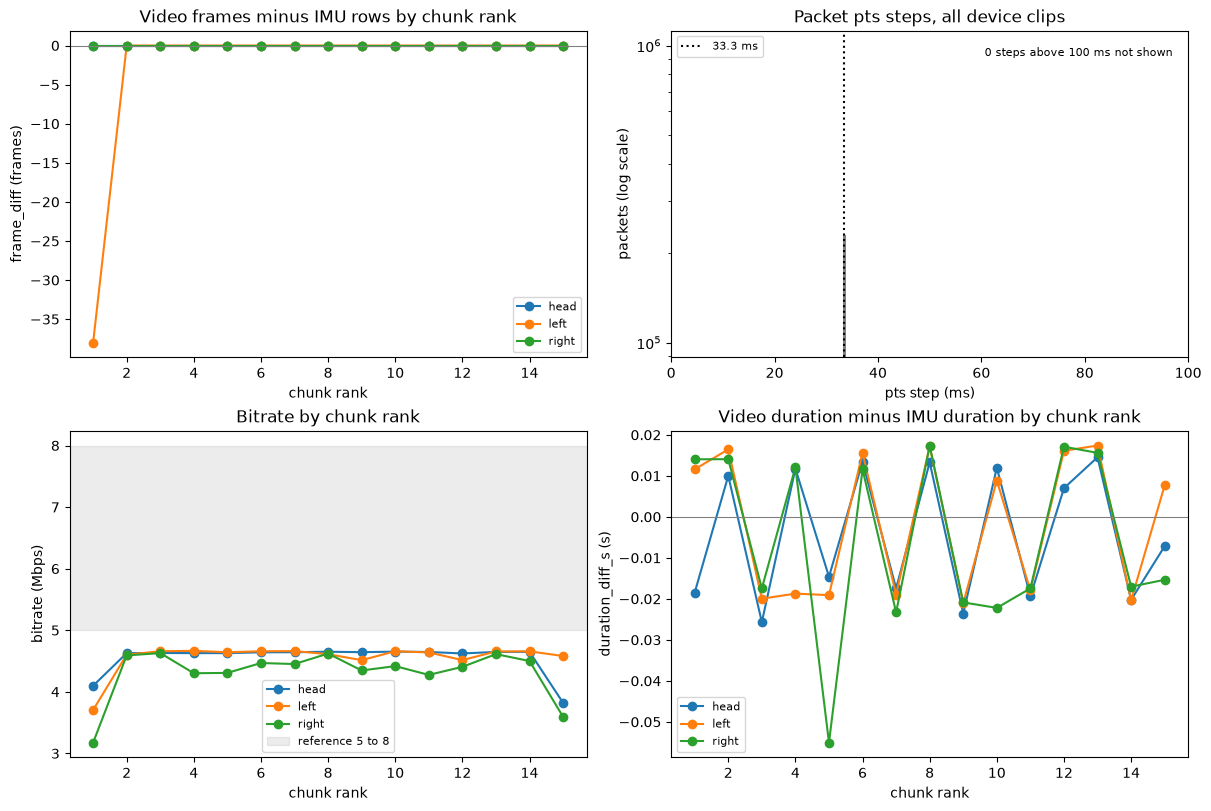

saved reports\03_video_timing.png


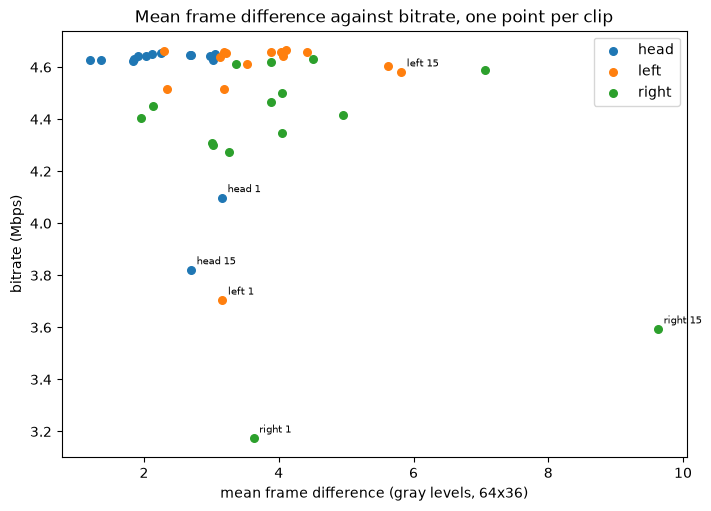

saved reports\03_motion_vs_bitrate.png


In [12]:
colors = {"head": "tab:blue", "left": "tab:orange", "right": "tab:green"}
vb = vs_df.merge(br[["base", "mbps"]], on="base", how="left")

fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for d in dev_order:
    s = vb[vb["device"] == d].sort_values("chunk_rank")
    ax[0, 0].plot(s["chunk_rank"], s["frame_diff"], "o-", color=colors[d], label=d)
    ax[1, 0].plot(s["chunk_rank"], s["mbps"], "o-", color=colors[d], label=d)
    ax[1, 1].plot(s["chunk_rank"], s["duration_diff_s"], "o-", color=colors[d], label=d)
ax[0, 0].axhline(0, color="gray", lw=0.8)
ax[0, 0].set_title("Video frames minus IMU rows by chunk rank")
ax[0, 0].set_xlabel("chunk rank"); ax[0, 0].set_ylabel("frame_diff (frames)")
ax[1, 0].axhspan(*EXPECTED["ref_mbps"], color="gray", alpha=0.15, label="reference 5 to 8")
ax[1, 0].set_title("Bitrate by chunk rank")
ax[1, 0].set_xlabel("chunk rank"); ax[1, 0].set_ylabel("bitrate (Mbps)")
ax[1, 1].axhline(0, color="gray", lw=0.8)
ax[1, 1].set_title("Video duration minus IMU duration by chunk rank")
ax[1, 1].set_xlabel("chunk rank"); ax[1, 1].set_ylabel("duration_diff_s (s)")

# pts step histogram over all device clips
all_steps = []
for b in clips["base"]:
    a = load_npz(PTS_DIR / f"{b}.npz")
    if a is not None:
        p = np.sort(a["pts"][np.isfinite(a["pts"])])
        all_steps.append(np.diff(p) * 1000)
all_steps = np.concatenate(all_steps) if all_steps else np.array([])
if len(all_steps):
    shown = all_steps[all_steps <= 100]
    lo_b, hi_b = (np.floor(shown.min()) - 0.25, np.ceil(shown.max()) + 0.75) if len(shown) else (0, 100)
    ax[0, 1].hist(shown, bins=np.arange(lo_b, hi_b, 0.5), color="tab:gray")
    ax[0, 1].set_yscale("log")
    ax[0, 1].text(0.97, 0.95, f"{int((all_steps > 100).sum())} steps above 100 ms not shown", transform=ax[0, 1].transAxes,
                  ha="right", va="top", fontsize=8)
ax[0, 1].axvline(1000 / 30, color="k", ls=":", label="33.3 ms")
ax[0, 1].set_xlim(0, 100)
ax[0, 1].set_title("Packet pts steps, all device clips")
ax[0, 1].set_xlabel("pts step (ms)"); ax[0, 1].set_ylabel("packets (log scale)")
for a_ in (ax[0, 0], ax[0, 1], ax[1, 0], ax[1, 1]):
    a_.legend(fontsize=8)
fig.savefig(REPORTS / "03_video_timing.png", dpi=150)
plt.show()
print("saved reports\\03_video_timing.png")

# motion against bitrate
mb = clips[["base", "device", "chunk_rank"]].merge(fc[["base", "mean_motion"]], on="base").merge(br[["base", "mbps"]], on="base")
fig2, ax2 = plt.subplots(figsize=(7, 5), constrained_layout=True)
if len(mb):
    for d in dev_order:
        s = mb[mb["device"] == d]
        ax2.scatter(s["mean_motion"], s["mbps"], color=colors[d], label=d, s=30)
        for r in s[s["chunk_rank"].isin([1, 15])].itertuples():
            ax2.annotate(f"{d} {int(r.chunk_rank)}", (r.mean_motion, r.mbps), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax2.legend()
else:
    ax2.text(0.5, 0.5, "no decoded clips, no motion values", ha="center", transform=ax2.transAxes)
ax2.set_title("Mean frame difference against bitrate, one point per clip")
ax2.set_xlabel("mean frame difference (gray levels, 64x36)"); ax2.set_ylabel("bitrate (Mbps)")
fig2.savefig(REPORTS / "03_motion_vs_bitrate.png", dpi=150)
plt.show()
print("saved reports\\03_motion_vs_bitrate.png")

## 13. Summary and zip

This step writes the summary json, builds the zip for sharing and prints a short summary.

In [13]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, (Path, pd.Timestamp)):
        return str(o)
    return o

per_dev = {}
for d in dev_order:
    s = vs_df[vs_df["device"] == d]
    per_dev[d] = {"clips": int(len(s)), "total_frames": float(s["frames"].sum()),
                  "total_duration_min": float(s["video_duration_s"].sum() / 60),
                  "imu_rows": float(s["imu_rows"].sum())}
total_frames = float(vs_df["frames"].sum())
n_pass = int((hyp_df["result"] == "PASS").sum())
n_flag = int((hyp_df["result"] == "FLAG").sum())
n_info = int((hyp_df["result"] == "INFO").sum())

summary = {
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "counts": {"files_in_manifest": int(len(vids)), "files_probed_ok": int(len(probe_df) - len(probe_errors)),
               "probe_failures": len(probe_errors), "packet_failures": len(pkt_errors),
               "device_files": int((~vids["is_root"]).sum()), "device_clips": int(len(clips)),
               "clips_decoded": int(len(fc)), "decode_failures": len(decode_fail), "root_files": int(len(root))},
    "formats_device_files": dev_groups.to_dict("records"),
    "formats_root": root_groups.to_dict("records"),
    "fps_values": sorted(pd_clips["avg_frame_rate"].dropna().round(3).unique().tolist()),
    "resolutions": sorted(pd_clips["res"].dropna().unique().tolist()),
    "per_device": per_dev, "total_frames": total_frames,
    "bitrate": br_stats.to_dict("records"), "gb_per_hour_three_cameras": float(three_cam),
    "root_video": root_info,
    "stream_copy_ok_clips": int(sc["copy_ok"].sum()),
    "tests": hyp_df.to_dict("records"),
    "tests_summary": {"pass": n_pass, "flag": n_flag, "info": n_info},
}
try:
    (REPORTS / "03_summary.json").write_text(json.dumps(clean(summary), indent=1), encoding="utf-8")
    print("saved reports\\03_summary.json")
except OSError as e:
    print("could not write summary:", e)

# zip with the report files of steps 2 to 13, no interim files
zip_names = ["03_probe_summary.csv", "03_packet_timing.csv", "03_frame_checks.csv", "03_freeze_runs.csv",
             "03_video_vs_imu.csv", "03_time_tags.csv", "03_bitrate.csv", "03_stream_copy_check.csv",
             "03_contact_head.png", "03_contact_left.png", "03_contact_right.png", "03_contact_root.png",
             "03_hypothesis_check.csv", "03_video_timing.png", "03_motion_vs_bitrate.png", "03_summary.json"]
zip_path = REPORTS / "share_03.zip"
missing_files = []
try:
    tmp = REPORTS / "share_03.zip.tmp"
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as z:
        for n in zip_names:
            if (REPORTS / n).exists():
                z.write(REPORTS / n, arcname=n)
            else:
                missing_files.append(n)
    os.replace(tmp, zip_path)
except OSError as e:
    print("could not write zip:", e)

print("\nsummary")
print(f"files probed: {len(probe_df) - len(probe_errors)} of {len(probe_df)}")
print(f"clips decoded: {len(fc)} of {len(clips)}")
print(f"tests: {n_pass} passed, {n_flag} flagged, {n_info} info")
print(f"total frames (45 clips): {total_frames:,.0f}")
print(f"resolution {summary['resolutions']}, fps {summary['fps_values']}")
if missing_files:
    print("not in zip (missing):", missing_files)
print("zip:", zip_path)

saved reports\03_summary.json

summary
files probed: 47 of 47
clips decoded: 45 of 45
tests: 7 passed, 5 flagged, 3 info
total frames (45 clips): 230,469
resolution ['1920x1080'], fps [30.0]
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_03.zip
